<a href="https://colab.research.google.com/github/johnryantaylor/QCES/blob/main/Project1_numerical_methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Heat transport

In this project we will discretize and timestep two systems that describe heat transport. In the first part we will timestep a box model for the Earth's surface temperature with heat buffering provided by the deep ocean. In the second part, we will timestep the one-dimensional diffusion equation which can be used to describe heat moving through a medium (e.g. the ground or still air and water).

Through this project, we will learn how to efficiently timestep ordinary and partial differential equations and examine errors introduced by the numerical discretization. We will also have the chance to explore the timescales and physical processes involved in heat transport in the climate system.

## 1. Climate box model

In this part of the project we will timestep the following box model.

$$ C_s \partial_t T = F(t) - \gamma(T-\theta) $$

$$ C_d \partial_t \theta = \gamma (T-\theta) $$

Here, $T(t)$ represents the global mean surface temperature as a function of time and $\theta(t)$ is the temperature of the deep ocean, both expressed as the difference between the temperature and a pre-industrial equilibrium in units of $^\circ K$. The net surface heat flux, $F(t)$, drives departures from the pre-industrial temperatures. The heat flux between the surface and deep ocean is assumed to be proportional to the difference between the surface and deep ocean temperatures. The constants are the heat capacity of the surface of the Earth, $C_s$, the heat capacity of the deep ocean, $C_d$, and the heat flux coefficient, $\gamma$, all given in units of $W/^\circ K/m^2$. Note that $C_s$ and $C_d$ (as defined in Nicklas et al. 2025) are heat capacities per year; i.e. $1/C_s$ tells us how much the surface temperature would increase if a flux of 1 $W/m^2$ were applied for one year.

This model is inspired by a more complicated version of a two box climate model in the paper referenced below. (Interested students might consider adding some additional features from their model, but this is not required for this project).

*Nicklas, J.M., Fox-Kemper, B. and Lawrence, C., 2025. Efficient Estimation of Climate State and Its Uncertainty Using Kalman Filtering with Application to Policy Thresholds and Volcanism. Journal of Climate, 38(5), pp.1235-1270.*

Below, we start to build code to solve these equations. Execute the code cells below.  In some cases you will be asked to add code.

Student tasks are in [Section 1.1](#section1pt1), [Section 1.2](#section1pt2), and [Section 1.3](#section1pt3).

In [40]:
# Before we start, import necessary libraries. Run this cell first.
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import time

Now, let's define values for the various constants. These values are taken from Nicklas et al., 2025.

In [41]:
C_s = 17 # heat capacity of the Earth's surface (W/m^2/K)
C_d = 156 # heat capacity of the deep ocean (W/m^2/K)
gamma = 0.67 # heat exchange coefficient between surface and deep ocean (W/m^2/K)

Now, let's define a function for F(t), the net surface heat flux (in units of $W/m^2$) that will force our model. This function is here to represent the heat imbalance caused by antropogenic greenhouse gases in the atmosphere. When $F=0$, there is no net surface heat flux. The argument, $t$, is the time in years. We will let $t=0$ denote the start of our additional warming, and we set $F=1$ if $t<200$ years and $F=0$ if $t>200$ years. This corresponds to a very bad-case emissions scenario with an abrupt drop in emissions after 200 years.

In [42]:
def F(t):
    return 1 if t < 200 else 0

Next, set the initial conditions. We will use arrays `T` and `theta`. `T[i]` represents the ith value in the array. We will use `T[0]` and `theta[0]` to hold the initial conditions. Subsequent values, `T[2]`, `T[3]`, etc. will be determined by timestepping the equations. We start by initializing the arrays using numpy and filling them with zeros and then set the initial values (this isn't necessary here since our values are zero anyway, but the code is here to that you can change the initial conditions easily)

In [43]:
Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)

Now, create an array with the time (in years) corresponding to each time index. Also, calculate the timestep, `dt`.

In [44]:
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

Finally, we are ready to create a for loop to timestep the equations listed at the top of the section.

### 1.1 Student task:
<a id='section1pt1'></a>
Fill in the interior of the for loop to timestep the equations from the start of Section 1 using the Explicit Euler method.

In [45]:
for i in range(0, Nt-1):
    T[i+1] = T[i] + dt*(1/C_s)*(F(t[i])- gamma*(T[i]-theta[i]))
    theta[i+1] = theta[i] + dt*(1/C_d)*(gamma*(T[i]-theta[i]))

After you are finished, run the cell below to plot the results

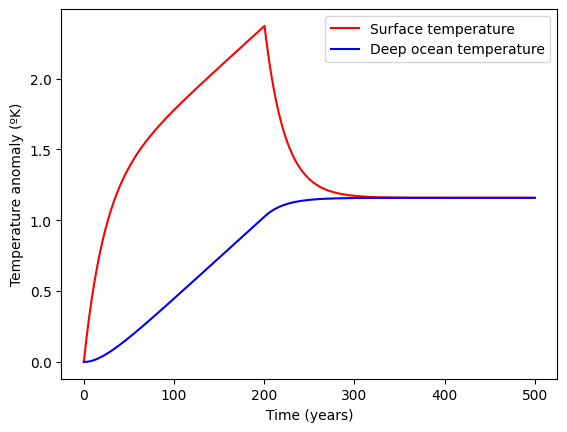

In [46]:
plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

### 1.2 Student task
<a id='section1pt2'></a>
Discuss the rates of change the temperature of the Earth's surface and the deep ocean at the start of the model run.  Can you explain the response of $T$ and $\theta$ to the forcing by defining characteristic timescales from the box model equations?

At the start of the model, both the surface and the deep ocean temperature have a temperature anomaly of zero (hence the T - theta term in both box equations is zero). This reflects the theta curve, which initially has dtheta/dt = 0, but this rate increases as the difference between theta and T grows and heat flows from the surface to the deep ocean. This also reflects the response of T, which does not require a nonzero (T-theta) for the temperature to change. dT/dt will be initially equal to 1/C_s but this rate decreases the more T rises, as more heat will be transferred to the deep ocean. T has a quicker but decreasing rate of change whilst theta changes at a slower rate, reliant on the heat transfer from the surface. After 100 years the rate of surface temperature noticeably slows and there is a nearly constant rate of change between 100-200 years. The surface temperature then peaks at 200 years when the flux is removed. From this point the surface ocean temperature drops rapidly and the deep ocean temperature plateaus. Since F(t) is programmed so that F=1 until t = 200 (years) and F=0 thereafter, the system reacts to the forcing being withdrawn after 200 years. Using the box model equations at F=0 we find that dT/dt can be scaled by a factor of -C_s/gamma and dtheta/dt is scaled by a factor of C_d/gamma. These characteristic timescales explain why there is a rapid decrease of T until it meets theta in a quasi-equilibrium state, when heat is shared between the two systems.



### 1.3 Student task
<a id='section1pt3'></a>
Modify the forcing function, `F(t)` above with 2-3 scenarios of your choice. Plot the temperature response for each scenario and briefly (2-3 sentences each) describe the temperature responses in each scenario. You will need to replicate some of the code blocks above so that you can produce a new set of plots below.

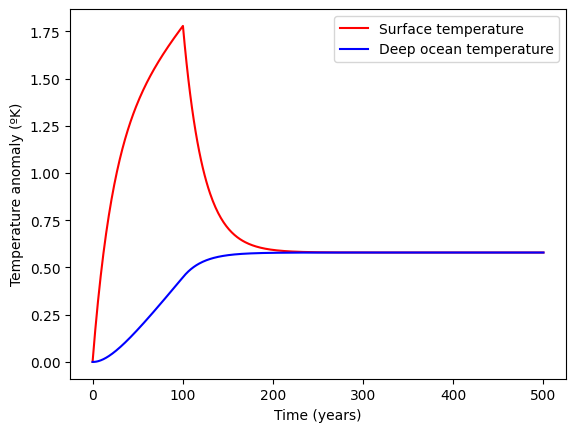

In [47]:
def F(t):
    return 1 if t < 100 else 0

Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt*(1/C_s)*(F(t[i])- gamma*(T[i]-theta[i]))
    theta[i+1] = theta[i] + dt*(1/C_d)*(gamma*(T[i]-theta[i]))

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

Here, I have shortened the applied forcing to 100 years instead of 200. Since the forcing stops earlier, the peak of T is stopped earlier, and the slightly slower rate of dT/dt at higher temperatures where more heat is being transferred to the deep ocean is not seen (only the rapid rise included in plot). Similarly to the previous plot, T falls quickly and settles into a quasi-equilibrium with the deep ocean once the forcing is removed, this equilibrium occurs earlier, as expected as the forcing is applied for less time. This quasi-equilibrium occurs at an anomaly of ~0.6K which is around half of the previous anomaly of ~1.25K, which also reflects the fact that half of the original heat flux was added.

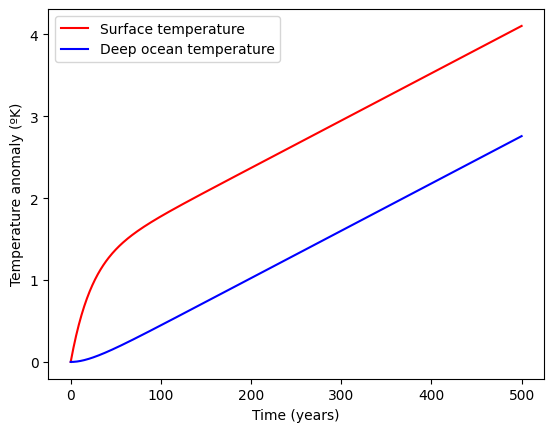

In [48]:
def F(t):
    return 1

Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt*(1/C_s)*(F(t[i])- gamma*(T[i]-theta[i]))
    theta[i+1] = theta[i] + dt*(1/C_d)*(gamma*(T[i]-theta[i]))

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

Here, I have used the same code as the original but instead of removing the forcing at t=200, the forcing is never removed and remains as F=1. This means that both T and theta do not ever cool back into a quasi equilibrium state. Behaviour seen previously such as a rapid rise of T, and a gradient of dtheta/dt = 0 initially are both expected and observed. However, after 100 years both curves increase at a steady and parallel rate, with a difference of ~1.4K between the two. This temperature difference ensures that both curves continue rising, and that heat from the surface continues to be transferred to the deep ocean.

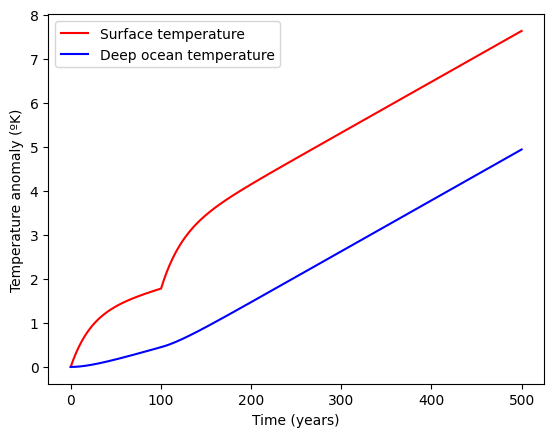

In [49]:
def F(t):
    return 1 if t < 100 else 2

Nt = 500 # number of time steps (including the starting point)
T = np.zeros(Nt) # surface temperature array
theta = np.zeros(Nt) # deep ocean temperature array
T[0] = 0 # initial surface temperature anomaly (ºK)
theta[0] = 0 # initial deep ocean temperature anomaly (ºK)
t = np.linspace(0, 500, Nt) # time in years.  This starts at 0 and ends at 500, with Nt total points
dt = t[1] - t[0] # timestep in years

for i in range(0, Nt-1):
    T[i+1] = T[i] + dt*(1/C_s)*(F(t[i])- gamma*(T[i]-theta[i]))
    theta[i+1] = theta[i] + dt*(1/C_d)*(gamma*(T[i]-theta[i]))

plt.plot(t,T,'r-')
plt.plot(t,theta,'b-')
plt.legend(['Surface temperature','Deep ocean temperature'])
plt.xlabel('Time (years)')
plt.ylabel('Temperature anomaly (ºK)')
plt.show()

Here, I have continued with a forcing of F=1 until 100 years, as done previously, but after 100 years I have applied a forcing of F=2, and have not withdrawn the forcing. The first 100 years responds similarly to my first new scenario, where T rises rapidly and then the rise of T slows as more heat is transferred to the deep ocean. After 100 years there is a second rapid rise in T, once again rising at a more rapid rate. The deep ocean does not settle into an equilibrium after this point because there is a now a significant (T-theta) term and both T and theta rise at a set constant rate in parallel.

## 2. Diffusion equation

In this part of the project we will solve the 1-D diffusion equation:

$$ \partial_t c = \kappa \partial_x^2 c $$

We will use second order finite differences to approximate the $x$-derivatives, and we will implement and compare two timestepping methods.

Student tasks are in [Section 2.1](#section2pt1) and [Section 2.2](#section2pt2).

First, let's discretize the second order derivative using finite differences. The function below builds a coefficient matrix, $M$, so that $Mc$ is a discretized version of $\partial^2_x c$, where in our discretized version $c$ is a column vector.

In [50]:
def construct_M(x):
    # Build a coefficient matrix, such that M*c is the discrete version of d^2/dx^2(c)
        dx = x[1] - x[0]  # Infer the uniform grid spacing
        Nx = len(x)  # Number of gridpoints
        M = (np.diag(np.ones(Nx-1), -1) - 2*np.diag(np.ones(Nx), 0) + np.diag(np.ones(Nx-1), 1)) / dx**2
        # Impose dc/dx=0 at both ends using ghost points (c[-1]=c[1] and c[Nx]=c[Nx-2])
        M[0, 1] = 2 / dx**2
        M[-1, -2] = 2 / dx**2
        M = sp.csr_matrix(M) # Turn M into a sparse matrix to save memory and improve speed
        return M

Now, define two functions to timestep the diffusion equation. The code below timesteps the diffusion equation using the expicit Euler method. The function takes in a vector of discrete positions, `x`, discrete times, `t`, and the diffusivity, `kappa`. The vectors `x` and `t` dictate the discretization of the problem in space and time, and the grid spacing must be constant in space and time. The boundary conditions are $\partial_x c=0$ at the starting and ending points in `x`.

In [51]:
def EE(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the explicit Euler and second order finite difference methods

    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt):  # loop over the number of timesteps
      c[:,k] = c[:,k-1] + dt * kappa * M @ c[:,k-1]

    end_time = time.time()  # Print the elapsed time

    print(f"Explicit Euler method took {end_time - start_time:.2f} seconds")

    return c

Similarly, the function below timesteps the diffusion equation with the Crank-Nicolson method

In [52]:
def CN(x, t, kappa):
# This function timesteps the diffusion equation with homogeneous Neumann boundary conditions
# using the Crank-Nicolson and second order finite difference methods
    start_time = time.time()  # Start a timer

    # Infer the timestep from the time array
    dt = t[1] - t[0]

    M = construct_M(x)  # Construct the coefficient matrix for the second derivative (including the boundary conditions)

    # Set the number of gridpoints in x and t
    Nx = len(x); Nt = len(t)

    A = sp.eye(Nx) - 0.5 * dt * kappa * M  # This matrix appears on the LHS in the C-N scheme
    A_solve = spla.factorized(A.tocsc()) # LU-factorize A (this only needs to be done once)

    # Create an empty sparse array to store the solution
    c = np.zeros((Nx, Nt))

    c[:, 0] = set_ics(x, kappa, 10)  # Set the initial condition

    for k in range(1, Nt): # loop over the number of timesteps
        c[:, k] = A_solve(c[:, k-1] + 0.5 * dt * kappa * (M @ c[:, k-1]))

    end_time = time.time()  # Print the elapsed time

    print(f"Crank-Nicolson method took {end_time - start_time:.2f} seconds")

    return c

Next, create a function to set the initial conditions. The exact solution to the unbounded diffusion equation with a delta function initial condition is:

$$\left(\frac{1}{4\pi\kappa t}\right)^{1/2}e^{-x^2/(4\kappa t)}$$

The function below sets the initial condition by evaluating the exact solution at a given time. Note that it is important that we don't evaluate the exact solution at `t_ic=0` since this will return a delta function which will be undefined on our finite grid. The value of `t_ic` is set within the `EE` and `CN` functions.

In [59]:
# Function to set the initial condition from the exact solution at time t_start
def set_ics(x, kappa, t_ic):
    c_ic = (4*np.pi*kappa*t_ic)**(-0.5)*np.exp(-x**2 / (4*kappa*t_ic))
    return c_ic


Finally, define some parameters and the x and t vectors:

In [64]:
# Defining parameters
kappa = 0.001  # diffusivity

# Timestepping parameters
t_start = 0  # start time (note that this is not the same time used to evaluate the exact solution to set the ICs)
t_end = 10  # end time
Nt = 1000  # number of timesteps

# Size of the physical domain
x_start = -1
x_end = 1
Nx = 100

t = np.linspace(t_start, t_end, Nt)  # Create a vector of times
x = np.linspace(x_start, x_end, Nx)  # Create a vector for x

Run each method once:

In [65]:
# Run the simulations
c_EE = EE(x, t, kappa) # explicit Euler
c_CN = CN(x, t, kappa) # Crank-Nicolson

Explicit Euler method took 0.04 seconds
Crank-Nicolson method took 0.01 seconds


and finally, plot the results side-by-side

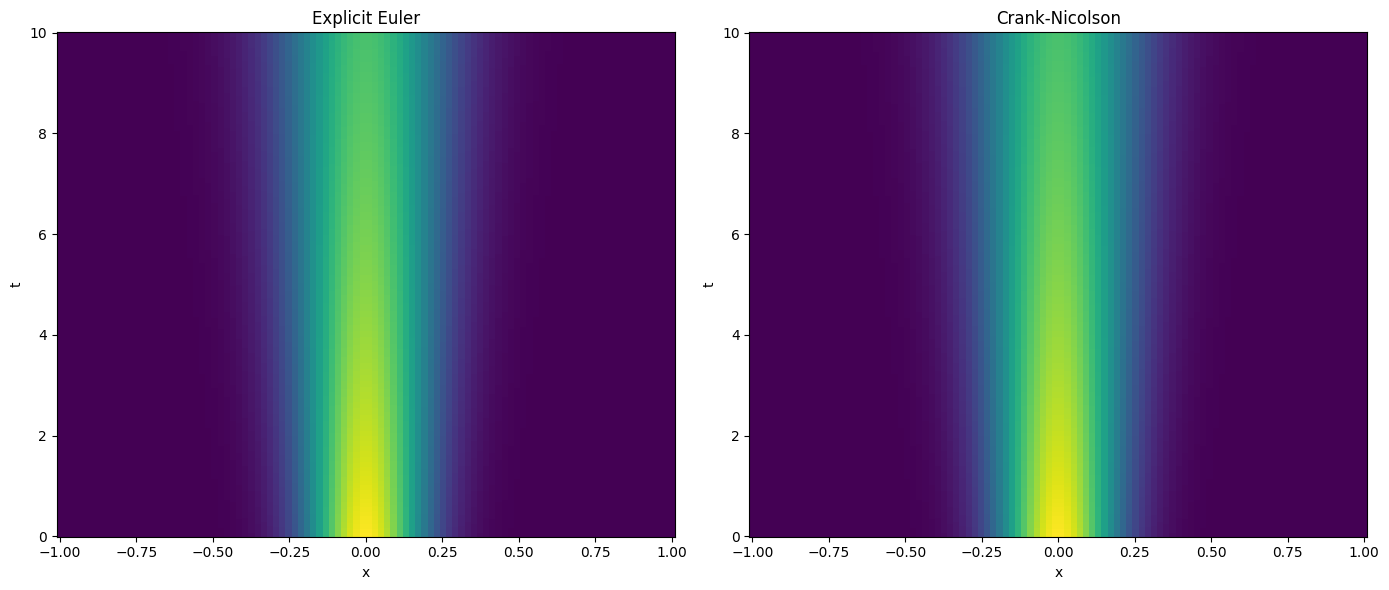

In [66]:
# Plot the results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.pcolormesh(x, t, c_EE.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Explicit Euler')

plt.subplot(1, 2, 2)
plt.pcolormesh(x, t, c_CN.T, shading='auto')
plt.xlabel('x')
plt.ylabel('t')
plt.title('Crank-Nicolson')

plt.tight_layout()
plt.show()

## 2. Student investigation

### 2.1 Stability
<a id='section2pt1'></a>
The explicit Euler and Crank-Nicolson methods have different stability properties. To explore this, try increasing the diffusivity, $\kappa$, and see how each method responds. Discuss your findings below (~2-3 sentences).

For diffusivity 𝜅 = 0.001, explicit Euler (EE) and Crank-Nicolson (CN) produce identical plots of the diffusion of x over time, with x appearing bright and highly concentrated at the beginning of the simulation, and diluting in colour over time. The concentration also spreads out horizontally to ~ -0.3 by t=10. However, the explicit Euler method took 0.14 seconds and Crank-Nicolson method took 0.05 seconds, i.e. the EE method is almost 3 times faster than CN. At k = 0.01 both EE and CN show high levels of diffusion and are stable (although they do differ, EE displays wider concentration diffusion). Although at 0.02 both work, at 0.03 EE appears unstable and displays a uniform spread of concentration. Once 𝜅 is increased to 0.05 (corresponding to an Nt~50), CN shows high level of diffusion, but EE is unstable and fails.

### 2.2 Accuracy
<a id='section2pt2'></a>
Next, we will examine the accuracy of the numerical methods used above. In order to do this, it is useful to compare our numerical solutions with the exact solution to the diffusion equation. Below, write code to plot the exact solution and the numerical solution using explicit Euler and Crank-Nicolson at the final time ($t=10$). Note that you can use the exact solution to the diffusion equation in an unbounded domain in $x$ and keep in mind that the exact solution and numerical solutions will differ for later times when boundary effects are felt.

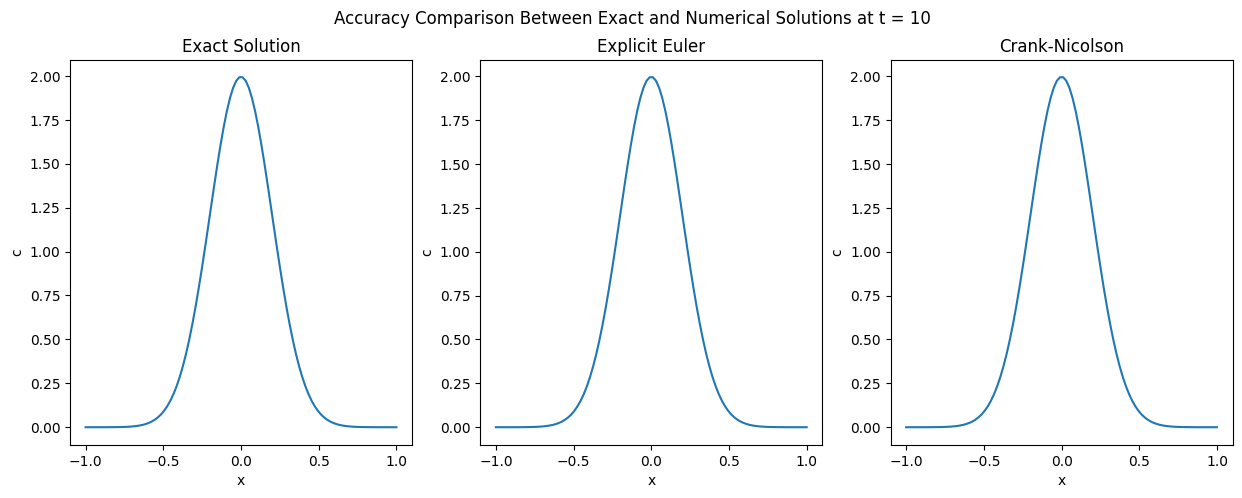

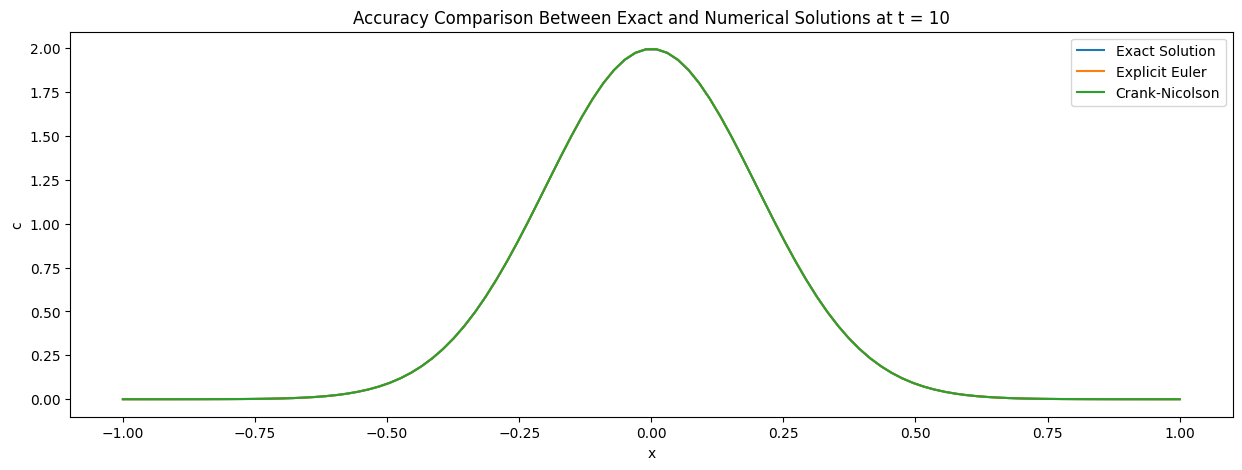

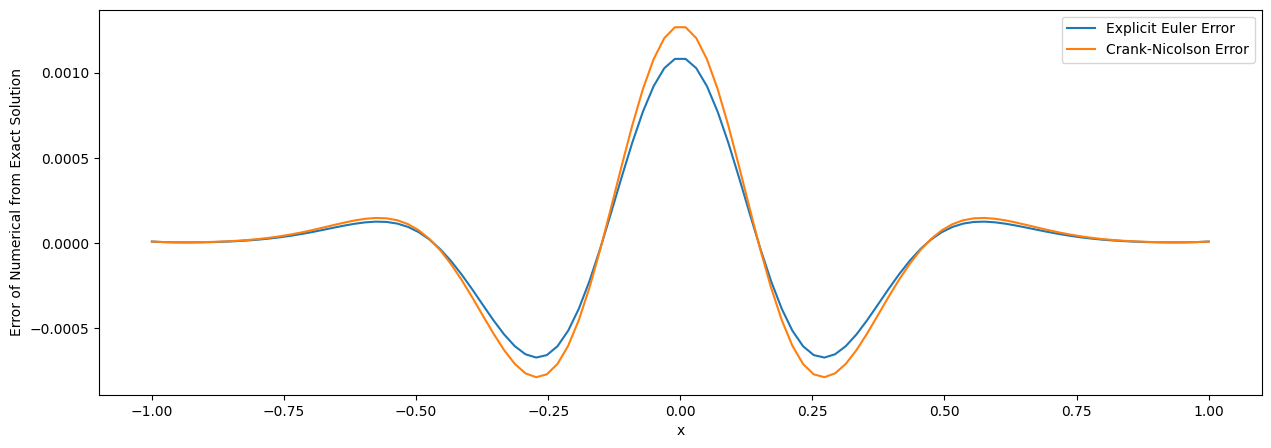

In [67]:
#simulations code means that t_ic starts at 10 so the final exact time is actually at t = t_ic + 10 = 20, below plotting EE, CN and exact solution at t = 20

c_exact = set_ics(x, kappa, 20)

# Solutions at final time
plt.figure(figsize=(15, 5))
plt.suptitle('Accuracy Comparison Between Exact and Numerical Solutions at t = 10')

plt.subplot(1, 3, 1)
plt.plot(x, c_exact)
plt.title('Exact Solution')
plt.xlabel('x')
plt.ylabel('c')

plt.subplot(1, 3, 2)
plt.plot(x, c_EE[:, -1])
plt.title('Explicit Euler')
plt.xlabel('x')
plt.ylabel('c')

plt.subplot(1, 3, 3)
plt.plot(x, c_CN[:, -1])
plt.title('Crank-Nicolson')
plt.xlabel('x')
plt.ylabel('c')

plt.show()


#check difference (error) of numerical solutions from the exact solution

plt.figure(figsize=(15, 5))
plt.plot(x, c_exact, label='Exact Solution')
plt.plot(x, c_EE[:, -1], label='Explicit Euler')
plt.plot(x, c_CN[:, -1], label='Crank-Nicolson')
plt.xlabel('x')
plt.ylabel('c')
plt.title('Accuracy Comparison Between Exact and Numerical Solutions at t = 10')
plt.legend()
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(x, c_EE[:, -1] - c_exact, label='Explicit Euler Error')
plt.plot(x, c_CN[:, -1] - c_exact, label='Crank-Nicolson Error')
plt.xlabel('x')
plt.ylabel('Error of Numerical from Exact Solution')
plt.legend()
plt.show()

When the exact, explicit Euler, and Crank-Nicolson solutions are plotted together, all curves overlap and appear incredibly accurate. Here, it seems that the EE and CN numerical approximations are both incredibly accurate and precise. Once an error plot is displayed (showing the difference of the numerical approximations to the exact solution, it is clear that both EE and CN solutions have similar errors at similar x values (x = -0.25, 0, and 0.25), this indicates that the errors are spatial errors and not timestepping errors. The CN solution is subject to slightly higher errors at these locations. Overall, these spatial errors are incredibly small the scale of 10^-5 and are likely due to the spatial discretisation of being bounded between +1 and -1, as such both solutions can be said to be accurate.

The difference between the exact solution and the numerical approximation can be quantified by various measures of error. The *local error* is the difference between the exact solution and the numerical approximation after one timestep. The *global error* is the difference between the solutions after a fixed amount of time (which includes the accumulation of multiple steps of local error). A method is first order accurate if the global error is linearly proportional to the timestep. A method is second order accurate if the global error varies quadratically with the timestep. Below, calculate and plot the global error for the Explicit Euler and Crank-Nicolson methods and use your results to infer the order of accuracy of each scheme.

Crank-Nicolson method took 0.27 seconds
Explicit Euler method took 0.00 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.00 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.00 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.00 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.01 seconds
Crank-Nicolson method took 0.00 seconds
Explicit Euler method took 0.01 seconds
Crank-Nicolson method took 0.01 seconds
Explicit Euler method took 0.02 seconds
Crank-Nicolson method took 0.01 seconds


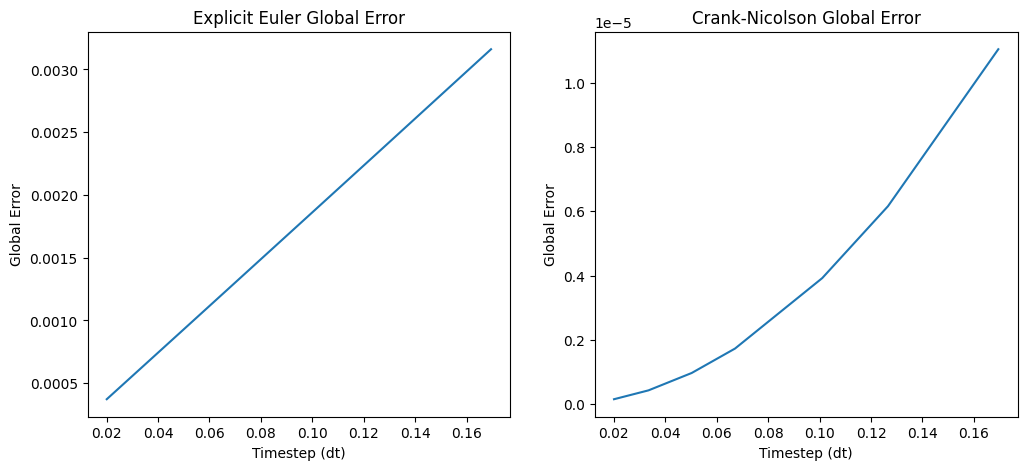

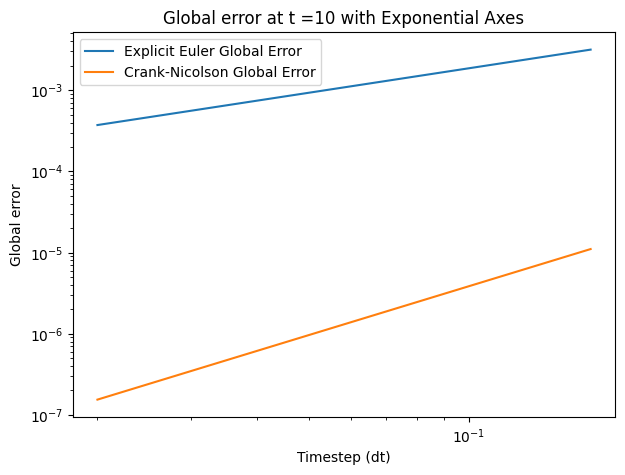

In [68]:
"""
  What I plotted previously is the global error after a fixed amount of time t = 10
  will need to find the global error per timestep and plot a figure of global vs timestep to see if it is linearly proportional or quadratic
  Picked a final time of t=10 as that has already been used previously, now will code to see how global error changes at t=10 when dt changes"""

#use a really small dt so that the time error doesn't intervene with the spatial error in the plot (otherwise plot dips and then time error dominates the error plot)
t_smalldt = np.linspace(t_start, t_end, 20000)
#keep last line of CN with small dt run aka final time with negligible time error
c_smalldt = CN(x, t_smalldt, kappa)[:, -1]

Nt_varied = np.array([60, 80, 100, 150, 200, 300, 500])
dt_axes = t_end / (Nt_varied - 1)
EE_error = np.zeros(len(Nt_varied))
CN_error = np.zeros(len(Nt_varied))

for i in range(len(Nt_varied)):
    t_i = np.linspace(t_start, t_end, Nt_varied[i])

    c_EE_i = EE(x, t_i, kappa)
    c_CN_i = CN(x, t_i, kappa)

# Calculating the global error as the maximum difference from the exact value, must be positive use only max value otherwise will end up with multiple error values per timestep, not useable to plot
    EE_error[i] = np.max(np.abs(c_EE_i[:, -1] - c_smalldt))
    CN_error[i] = np.max(np.abs(c_CN_i[:, -1] - c_smalldt))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(dt_axes, EE_error)
plt.xlabel('Timestep (dt)')
plt.ylabel('Global Error')
plt.title('Explicit Euler Global Error')

plt.subplot(1, 2, 2)
plt.plot(dt_axes, CN_error)
plt.xlabel('Timestep (dt)')
plt.ylabel('Global Error')
plt.title('Crank-Nicolson Global Error')
plt.show()

# plot a log-log plot
plt.figure(figsize=(7, 5))
plt.loglog(dt_axes, EE_error, label='Explicit Euler Global Error')
plt.loglog(dt_axes, CN_error, label='Crank-Nicolson Global Error')
plt.xlabel('Timestep (dt)')
plt.ylabel('Global error')
plt.title('Global error at t =10 with Exponential Axes')
plt.legend()
plt.show()


Here, both graphs are plotted using t=10 as done previously, with global error vs varying timestep discretisations. The EE plot shows that the global error is linearly proportional to the timestep and thus is first order accurate. Conversely, the CN plot shows that the global error varies quadratically with the timestep and thus is second order accurate.

Finally, select a given error tolerance and explore whether explicit Euler or Crank-Nicoslon is more efficient (faster) at generating solutions with error less than your error tolerance. Discuss your conclusion and add supporting figures if necessary.

From the linear global error vs timestep plot generated in the section above, I have selected an error tolerance of global error = 0.0005, as that is approximately the error found at the smallest timestep solution for EE. The errors found for CN at this timestep and at larger timesteps all pass this tolerance value. It is also clear from the lines where the simulation computed the solutions (e.g. Crank-Nicolson method took 0.00 seconds, Explicit Euler method took 0.01 seconds) that the CN method is faster for almost every timestep solution. Furthermore, it is clear that the CN method is more efficient (faster at generating more solutions) and has a lower spatial error that is within my error tolerance, whereas the EE solutions are slower and sometimes does not pass an error tolerance of global error = 0.0005.